# Fiche 5 — Construire un score pour classer des pays (et vérifier qu'il tient la route)

| | |
|---|---|
| 🎯 **Objectif** | Transformer plusieurs indicateurs en une recommandation défendable |
| ⏱️ **Durée** | 45 min |
| 🧰 **Prérequis** | Fiches 3 et 4 |
| 🔗 **Dans le projet** | Exercice partie 3, étape 2 (« méthode quantitative ») |

> **L'idée clé.** Un score est une **opinion chiffrée** : le choix des critères et des poids est un choix métier.
> Le travail du data analyst est de rendre ce choix **explicite**, **comparable** et **testé**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.io import load_tables

viz.apply_style()
pd.set_option("display.max_colwidth", 70)

classement = pd.read_csv("../data/processed/classement_pays.csv", index_col=0)
criteres = classement[["marche_connecte", "maturite_numerique", "dynamique"]]
criteres.describe().round(2)

,marche_connecte,maturite_numerique,dynamique
count,161.00,161.00,161.00
mean,2242830.60,39.61,0.38
std,8036495.36,28.48,0.48
min,5284.91,1.22,-0.29
25%,84514.82,12.58,0.03
50%,384464.18,37.10,0.24
75%,1190544.10,61.94,0.58
max,89564529.39,96.21,1.85


## 1. Le problème des unités

`marche_connecte` se compte en **millions de personnes**, `maturite_numerique` en **%** et `dynamique` en
**proportion**. Additionner ces nombres tels quels revient à laisser le plus grand nombre décider de tout.
Il faut d'abord les ramener sur une **même échelle**. Trois méthodes courantes :

In [2]:
x = criteres["marche_connecte"]
normalisations = pd.DataFrame({
    "min-max": (x - x.min()) / (x.max() - x.min()),
    "z-score": (x - x.mean()) / x.std(),
    "rang percentile": x.rank(pct=True),
})
normalisations.join(classement["Short Name"]).loc[["IND", "CHN", "USA", "FRA", "MAR"]].round(3)

,min-max,z-score,rang percentile,Short Name
Country Code,,,,
IND,0.337,3.473,0.988,India
CHN,1.000,10.866,1.000,China
USA,0.363,3.762,0.994,United States
FRA,0.069,0.489,0.925,France
MAR,0.039,0.154,0.857,Morocco


| Méthode | Formule | Avantage | Défaut |
|---|---|---|---|
| min-max | (x − min) / (max − min) | simple, entre 0 et 1 | **un seul géant** écrase tous les autres près de 0 |
| z-score | (x − moyenne) / écart-type | classique en statistique | même problème avec les données asymétriques |
| **rang percentile** | rang / nombre de pays | robuste aux valeurs extrêmes | perd l'écart : 1ᵉʳ et 2ᵉ sont proches même si l'écart réel est énorme |

Le corrigé utilise le **rang percentile**. Avec le min-max, la Chine vaudrait 1, la France 0,07 et le Maroc 0,04 :
le critère ne distinguerait plus que la Chine du reste du monde.

## 2. Moyenne pondérée

In [3]:
from edstats.analysis import percentile_score

poids = {"marche_connecte": 0.5, "maturite_numerique": 0.3, "dynamique": 0.2}
score = percentile_score(criteres, poids)
classement.assign(score_recalcule=score).sort_values("score_recalcule", ascending=False).head(8)[
    ["Short Name", "marche_connecte", "maturite_numerique", "dynamique", "score_recalcule"]
].round(2)

,Short Name,marche_connecte,maturite_numerique,dynamique,score_recalcule
Country Code,,,,,
GBR,United Kingdom,6959078.49,87.48,0.21,0.85
FRA,France,6170693.33,81.44,0.20,0.82
USA,United States,32472803.48,71.69,0.08,0.80
RUS,Russia,11330800.89,63.80,0.14,0.80
ESP,Spain,3088725.30,69.81,0.32,0.78
DEU,Germany,7503384.34,82.35,-0.07,0.78
JPN,Japan,9821798.50,79.50,-0.06,0.78
MAR,Morocco,3477956.39,55.42,0.42,0.77


## 3. Le test qui manque presque toujours : la robustesse aux poids

Pourquoi 0,5 / 0,3 / 0,2 et pas 0,4 / 0,4 / 0,2 ? Si le top 10 change complètement, la recommandation dépend
**de nous**, pas des données. On tire donc 1 000 jeux de poids au hasard et on compte combien de fois chaque pays
entre dans le top 10.

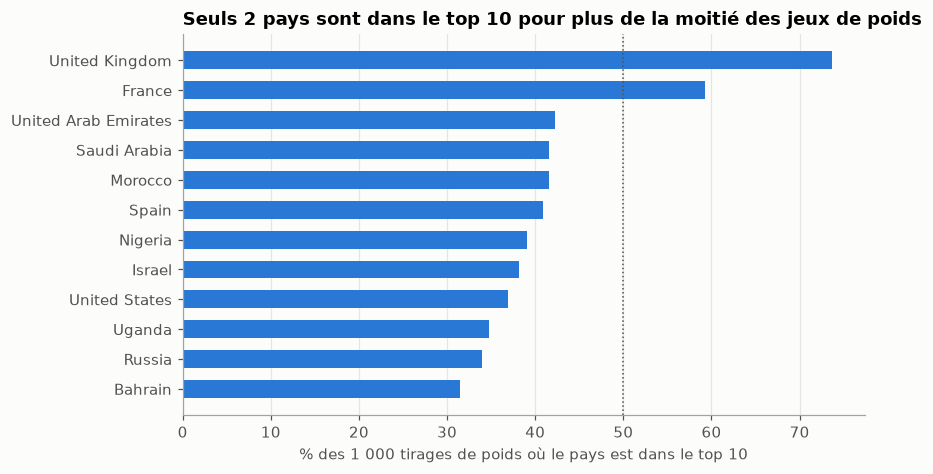

In [4]:
from edstats.analysis import weight_sensitivity

frequence = weight_sensitivity(criteres, list(poids), n_draws=1000, top=10, seed=42)
top_robuste = frequence.head(12).to_frame().join(classement["Short Name"])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top_robuste["Short Name"][::-1], top_robuste["frequence_top"][::-1] * 100, color=viz.BLUE, height=0.6)
ax.axvline(50, color=viz.TEXT_2, linestyle=":", linewidth=1)
ax.set(title="Seuls 2 pays sont dans le top 10 pour plus de la moitié des jeux de poids",
       xlabel="% des 1 000 tirages de poids où le pays est dans le top 10", ylabel="")
ax.grid(axis="y", visible=False)
viz.save(fig, "robustesse_poids")
plt.show()

**Lecture.** Le Royaume-Uni et la France sont des choix **robustes**. Les autres pays dépendent de l'importance
donnée à la croissance par rapport à la maturité. Ce n'est pas un échec de l'analyse : c'est **la question à poser
à Mark**. Veut-il un marché solvable tout de suite, ou un marché qui grandit ?

## 4. Pourquoi les critères ne doivent pas être redondants

In [5]:
criteres.corr(method="spearman").round(2)

,marche_connecte,maturite_numerique,dynamique
marche_connecte,1.00,0.38,-0.26
maturite_numerique,0.38,1.00,-0.66
dynamique,-0.26,-0.66,1.00


Si on ajoutait le PIB par habitant **en plus** du taux d'internet (ρ ≈ 0,9 entre eux), le « niveau de
développement » compterait **deux fois** dans le score, sans que personne l'ait décidé. Supprimer les redondances
(fiche 3) sert exactement à cela.

### ✍️ À toi de jouer

Mark annonce : « la croissance compte autant que la taille du marché ». Recalcule le score avec les poids 0,4 / 0,2 / 0,4. Quels pays entrent dans le top 10, et lesquels en sortent ?

In [6]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
nouveau = percentile_score(criteres, {"marche_connecte": 0.4, "maturite_numerique": 0.2, "dynamique": 0.4})
avant = set(score.nlargest(10).index)
apres = set(nouveau.nlargest(10).index)
noms = classement["Short Name"]
print("entrent :", noms[list(apres - avant)].tolist())
print("sortent :", noms[list(avant - apres)].tolist())
```

Entrent : Nigeria, Ouganda, Soudan, Israël (cible en forte croissance). Sortent : États-Unis, Russie, Allemagne, Japon (cible stable ou en baisse). C'est l'arbitrage maturité / croissance rendu visible : changer les poids, c'est changer de stratégie.
</details>

## ✅ À retenir

1. Normaliser avant de combiner ; le rang percentile résiste aux géants.
2. Les poids sont un **choix métier** : on les écrit, on les justifie.
3. On **teste** leur influence (tirages aléatoires) : seule une recommandation qui résiste est solide.
4. Critères redondants = double comptage caché.
5. Un score trie des pays ; il ne prédit pas un chiffre d'affaires.